<div style="display:flex">

<div>

<h1 style="font-weight:bold">Geo Guesser</h1>

<p style="line-height:2">
<a link="https://www.geoguessr.com/" target="_blank">GeoGuesser</a> is a browser-based geography game developed by Anton Wallén, a Swedish IT consultant, which was first released on 9 May 2013.
The objective of the game is to guess the location in the world using only the clues visible. <br><br>
</p>

<span style="font-weight: bold; font-size: 18px;">How it works ?</span><br>

<p style="line-height:2">
The game uses a semi-randomized Google Street View location where the user can move around and explore the area.
When the user decides to make a guess, the game reveals how far away the user was from the correct location.
</p>
</div>

<div style="display:flex; width: 100%;  justify-content: center; align-items: center;">
<img src="https://www.malmstedt.nu/img/case/geoguessr/geoguessr-badge.png"/>
</div>

</div>

----

## Necessary Libraries

In [1]:
# Import inbuilt libraries
import os, shutil, pathlib
from math import sqrt, ceil

# Import necessary libraries for data analysis
import numpy as np
import pandas as pd

# Import necessary libraries for data visualization
from plotly.offline import init_notebook_mode, iplot
import plotly.graph_objects as go
import plotly.offline as pyo
import plotly.express as px

# Initialize Plotly for Jupyter notebook
init_notebook_mode(connected=True)

# Import necessary libraries for tensorflow
import tensorflow as tf
from keras.layers import Dense, Flatten, Dropout, RandomFlip, RandomRotation, RandomZoom, GlobalAveragePooling2D
from keras.models import Sequential, Model
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.applications import DenseNet121, EfficientNetB0, ResNet50

# Import necessary libraries for image processing
from PIL import Image

In [2]:
# Constants
img_width   = 224  # Image width for preprocessing
img_height  = 224  # Image height for preprocessing
random_seed = 123  # Set a fixed random seed for reproducibility
batch_size  = 32  # Define the batch size for training data

# File and directory paths
working_dir     = pathlib.Path().absolute()  # Path to the working directory
geo_data_dir    = pathlib.Path(os.path.join('/kaggle/input/geolocation-geoguessr-images-50k/compressed_dataset'))  # Path to the data directory
geo_train_dir   = pathlib.Path(os.path.join(working_dir, 'train_dataset'))  # Path to the train dataset directory
geo_test_dir    = pathlib.Path(os.path.join(working_dir, 'test_dataset'))  # Path to the test dataset directory

## Load Dataset

<br>

<span style="font-weight: bold; font-size: 18px;">Context :</span><br>
<p style="line-height:2">
The dataset comprises approximately 50,000 geoguesser images sourced from the GeoWorld challenge. It is organized into about 150 distinct subfolders, each dedicated to images from a specific country. Notably, the distribution of countries is non-uniform, resulting in each folder containing varying numbers of images, ranging from 1,000 to 12,000. Consequently, geoguessr games are not truly random, as certain countries are more prominently featured than others.
</p> <br>


In [3]:
# Function to extract metadata from a give file
def extract_metadata_from_folder(path):
    metadata = []
    for file_path in path.glob('*'):
        # Get the width and height of the image
        width, height = Image.open(file_path).size
        
        metadata.append({
            'country': path.name,
            'image_name': file_path.name,
            'width': width,
            'height': height,
            'size': file_path.stat().st_size,
            'path': file_path
        })
    
    return metadata

In [4]:
# List all country folders
country_folders = [f for f in os.listdir(geo_data_dir) if os.path.isdir(os.path.join(geo_data_dir, f))]

# Initialize an empty list to store metadata
all_metadata = []

# Iterate through country folders and extract metadata
for country_name in country_folders:
    metadata = extract_metadata_from_folder(pathlib.Path(os.path.join(geo_data_dir, country_name)))
    all_metadata.extend(metadata)

# Create a Pandas DataFrame from the metadata
df_geo_data = pd.DataFrame(all_metadata)
df_data_distribution = df_geo_data.groupby('country')['image_name'].count().reset_index().rename(columns={'image_name': 'frequency'})

df_geo_data.head()

,country,image_name,width,height,size,path
0,Bhutan,canvas_1629262074.jpg,1536,662,146162,/Users/crypticsy/Workspace/Kaggle/compressed_d...
1,Bhutan,canvas_1629527767.jpg,1536,662,144906,/Users/crypticsy/Workspace/Kaggle/compressed_d...
2,Bhutan,canvas_1629551780.jpg,1536,662,137721,/Users/crypticsy/Workspace/Kaggle/compressed_d...
3,Bhutan,canvas_1629992395.jpg,1536,662,145488,/Users/crypticsy/Workspace/Kaggle/compressed_d...
4,Bhutan,canvas_1629687800.jpg,1536,662,141312,/Users/crypticsy/Workspace/Kaggle/compressed_d...


View a random image from dataset

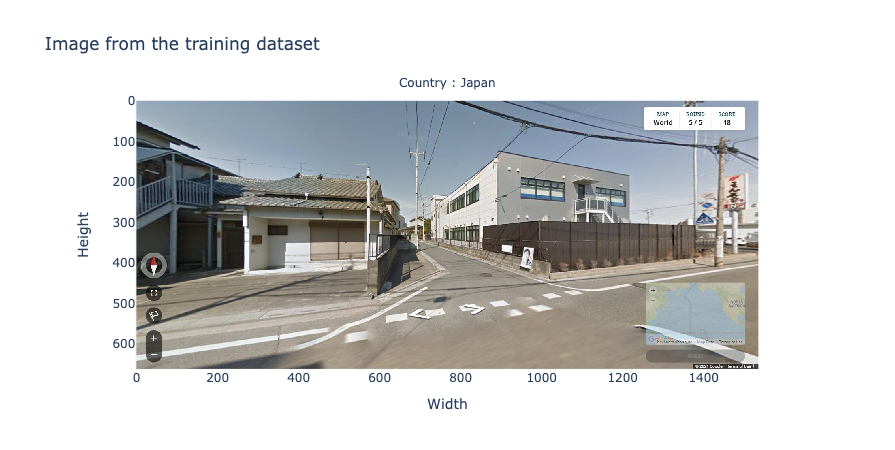

In [5]:
# select a random country
random_country = df_geo_data.sample(1)

with Image.open(random_country.path.values[0]) as img:
    fig = go.Figure()
    fig.add_trace(go.Image(z=img))
    fig.update_layout(
        title="Image from the training dataset",
        template="plotly_white",
        width=900,
        height=450
    )
    
    fig.update_xaxes(title_text="Width")
    fig.update_yaxes(title_text="Height")
    
    fig.add_annotation(
        x=0.5,
        y=1.1,
        xref="paper",
        yref="paper",
        text="Country : {}".format(random_country.country.values[0]),
        showarrow=False
    )
    
    fig.show()

----

## Exploratory Data Analysis
<br>

### Statistics

General distribution of the dataset

<p style="line-height:2">
To get a better understanding of the dataset, we look at the <br>
    <ul style="list-style-type:circle; line-height:2">
        <li>dimensions of the images</li>
        <li>number of images per country</li>
    </ul>
</p>

In [6]:
for dim in ['width', 'height']:
    if len(df_geo_data[dim].unique()) != 0:
        print("The images have different {}s.".format(dim))
        print("There are {} types of {} in the dataset: i.e. {} px.".format(len(df_geo_data[dim].unique()), dim, ' px & '.join(map(str, df_geo_data.width.unique()))))
        print("\n --- Distribution of {}s --- ".format(dim))
        display(df_geo_data.groupby('width').aggregate({'size': 'count', 'country':'nunique'}).reset_index().rename(columns={'size': 'frequency'}))
        print()

The images have different widths.

There are 2 types of width in the dataset: i.e. 1536 px & 1030 px.



 --- Distribution of widths --- 


,width,frequency,country
0,1030,55,28
1,1536,49942,124




The images have different heights.

There are 2 types of height in the dataset: i.e. 1536 px & 1030 px.



 --- Distribution of heights --- 


,width,frequency,country
0,1030,55,28
1,1536,49942,124


In [7]:
print("The total number of images in the dataset are {:,} images.".format(df_data_distribution.frequency.sum()))
print("The average number of images per country is {:,} images.".format(int(df_data_distribution.frequency.mean())))
print("The median number of images per country is {:,} images.".format(int(df_data_distribution.frequency.median())))
print("25% of the countries have {:,} images or less, while 75% of the countries have {:,} images or more.".format(int(df_data_distribution.frequency.quantile(0.25)), int(df_data_distribution.frequency.quantile(0.75))))
print("The maximum and minimum number of images per country are {:,} and {:,} images respectively.".format(df_data_distribution.frequency.max(), df_data_distribution.frequency.min()))

The total number of images in the dataset are 49,997 images.

The average number of images per country is 403 images.

The median number of images per country is 81 images.

25% of the countries have 13 images or less, while 75% of the countries have 268 images or more.

The maximum and minimum number of images per country are 12,014 and 1 images respectively.


<span style="font-weight: bold; font-size: 18px;">Pictures per Country</span><br><br>

<p style="line-height:2">
Using a boxplot, we can see that the number of images per country is not uniform. <br>
United States is an outlier with more than 12,000 images, which has skewed the distribution. <br>
</p>

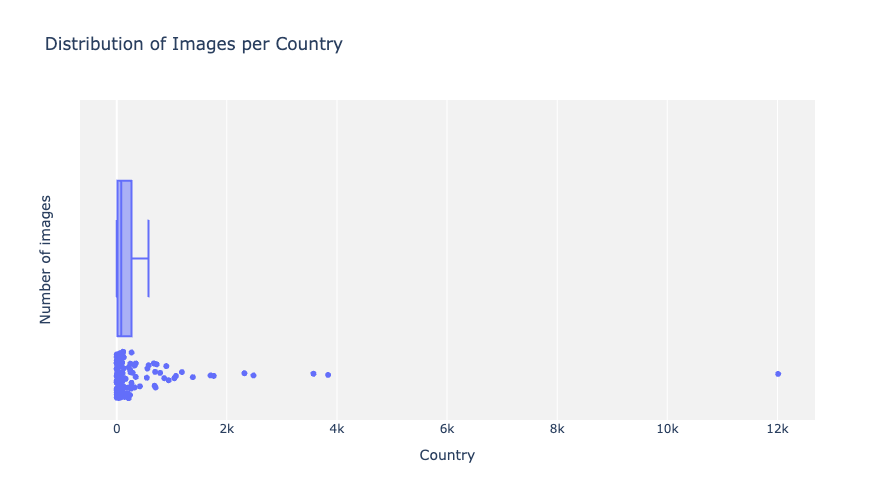

In [8]:
# Function to add custom styling to the plot
def add_plot_styling(fig):
    fig.update_layout(
        plot_bgcolor='rgba(0,0,0,0.05)',  # Set background color to transparent
    )
    return fig


fig = px.box(
    df_data_distribution, 
    x="frequency", 
    title="Distribution of Images per Country", 
    hover_data=["frequency"],
    points="all")

# change the dimensions of the figure
fig.update_layout(xaxis_title="Country", yaxis_title="Number of images", height=500)
fig = add_plot_styling(fig)

# Use iplot to display the graph in the Jupyter Notebook
iplot(fig)

<p style="line-height:2">
Using a heatmap, we can visualize the number of images available in the dataset. The color of the country is determined by the number of images available. On the color specturm, the light green represents the countries with the least number of images, while the dark green represents the countries with the most number of images.
</p>

In [9]:
# Function to plot heatmap
def plot_heatmap(df, title_text, color_threshold=0.90):
    # Shaping Data to fit graph by finding the max size of the grid to fit all the images
    grid_size = ceil(sqrt(df.shape[0]))**2
    
    pad = '-'
    n_labels = df.country.to_list() + ([pad] * (grid_size - df.shape[0]))
    n_samples = df.frequency.to_list() + ([np.nan] * (grid_size - df.shape[0]))
    
    samples = np.split(np.array(n_samples), sqrt(grid_size))
    
    fig = go.Figure(data=go.Heatmap(
        z=samples,
        x0=0,
        dx=1,
        y0=0,
        dy=1,
        colorscale='Emrld',
        text=n_labels,
        hoverinfo='text',
    ))
    
    # Add labels within the heatmap
    for i, country in enumerate(df['country']):
        x_pos = i % int(sqrt(grid_size))
        y_pos = i // int(sqrt(grid_size))
        fig.add_annotation(
            x=x_pos,  # Center the label within the grid cell
            y=y_pos,
            text= "{}<br> Count: {}".format(n_labels[i].replace(' ', '<br>'), n_samples[i]),
            showarrow=False,
            font=dict(
                color='#474747' if n_samples[i] < df.frequency.quantile(color_threshold) else 'white',
                size=10),
        )
    
    # hide axis labels
    fig.update_xaxes(showticklabels=False)
    fig.update_yaxes(showticklabels=False, autorange='reversed')
    
    # change the dimensions of the figure
    fig.update_layout(
        title=title_text,
        height=1200,
        width=1200
    )
    fig = add_plot_styling(fig)
    
    # Use iplot to display the graph in the Jupyter Notebook
    pyo.iplot(fig)

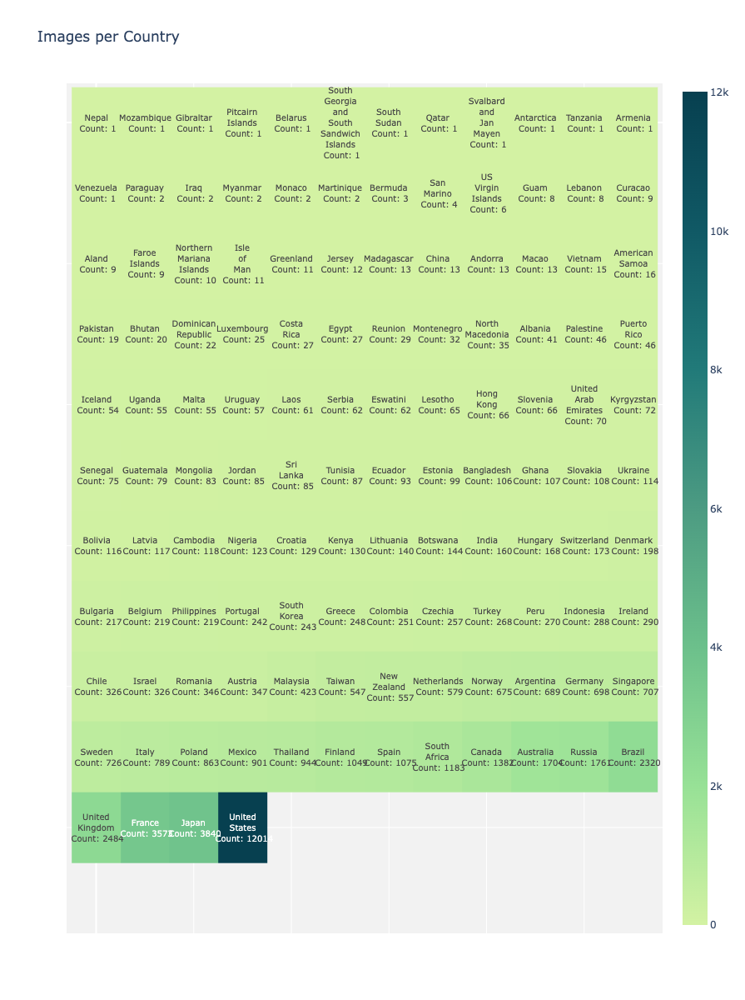

In [10]:
plot_heatmap(df_data_distribution.sort_values(by='frequency', ascending=True), "Images per Country", color_threshold=0.98)

Distribution of Dataset after removing outliers

The mean number of images per country after removing United States is 308 images.

The median number of images per country after removing United States is 79 images.


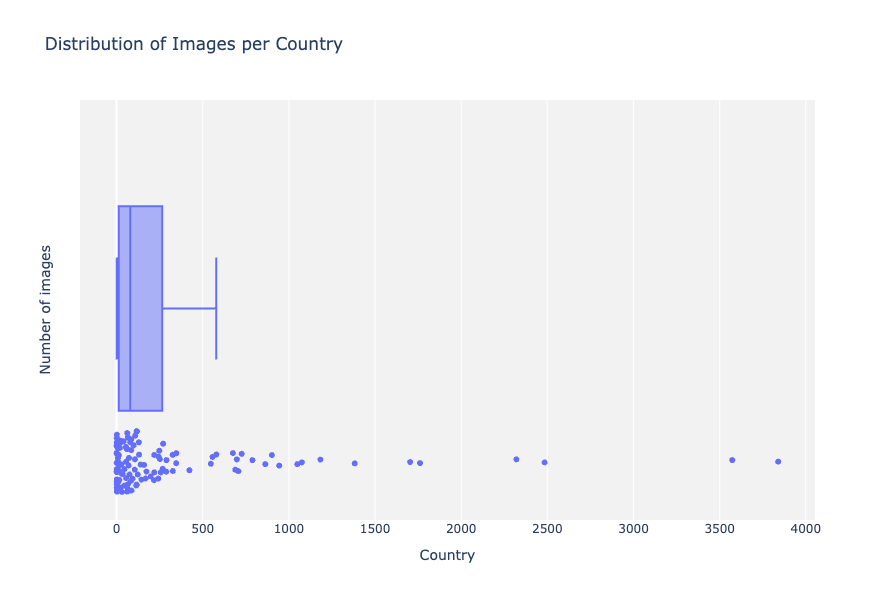

In [11]:
# removing the United States from the dataset
df_temp = df_data_distribution[df_data_distribution.country != 'United States']

print("The mean number of images per country after removing United States is {:,} images.".format(int(df_temp.frequency.mean())))
print("The median number of images per country after removing United States is {:,} images.".format(int(df_temp.frequency.median())))

fig = px.box(
    df_temp, 
    x="frequency", 
    title="Distribution of Images per Country", 
    hover_data=["frequency"],
    points="all")

# change the dimensions of the figure
fig.update_layout(xaxis_title="Country", yaxis_title="Number of images", height=600)
fig = add_plot_styling(fig)

# Use iplot to display the graph in the Jupyter Notebook
iplot(fig)

----

## Data Cleaning

### Filtering out countries with less than 80 pictures and outliers

<p style="line-height:2">
As the majority of the countries have more than 80 pictures, after removing the outliers, we filter out the countries with less than 80 pictures. <br>
To do so, we add a conditional `80 >= image_count <= 10000` because we want to have a good amount of pictures per country to train our model on.<br/>
</p>

In [12]:
# get the list of countries with more than 80 images
filtered_countries = df_data_distribution[(df_data_distribution.frequency >= 80) & (df_data_distribution.frequency <= 10000) ].country.unique()

# # get the list of top 20 countires
# filtered_countries = df_data_distribution[(df_data_distribution.frequency <= 10000)].sort_values(by='frequency', ascending=False).head(20).country.unique()

df_filtered_geo_data = df_geo_data[df_geo_data.country.isin(filtered_countries)]
df_filtered_distribution = df_filtered_geo_data.groupby('country')['image_name'].count().reset_index().rename(columns={'image_name': 'frequency'})

df_filtered_geo_data

,country,image_name,width,height,size,path
20,Kenya,canvas_1629925277.jpg,1536,662,152237,/Users/crypticsy/Workspace/Kaggle/compressed_d...
21,Kenya,canvas_1629837897.jpg,1536,662,147502,/Users/crypticsy/Workspace/Kaggle/compressed_d...
22,Kenya,canvas_1630278825.jpg,1536,662,96044,/Users/crypticsy/Workspace/Kaggle/compressed_d...
23,Kenya,canvas_1629433275.jpg,1536,662,156090,/Users/crypticsy/Workspace/Kaggle/compressed_d...
24,Kenya,canvas_1630286494.jpg,1536,662,134282,/Users/crypticsy/Workspace/Kaggle/compressed_d...
...,...,...,...,...,...,...
49936,Canada,canvas_1630010523.jpg,1536,662,190612,/Users/crypticsy/Workspace/Kaggle/compressed_d...
49937,Canada,canvas_1630102127.jpg,1536,662,126300,/Users/crypticsy/Workspace/Kaggle/compressed_d...
49938,Canada,canvas_1629746307.jpg,1536,662,116114,/Users/crypticsy/Workspace/Kaggle/compressed_d...
49939,Canada,canvas_1629686137.jpg,1536,662,159690,/Users/crypticsy/Workspace/Kaggle/compressed_d...


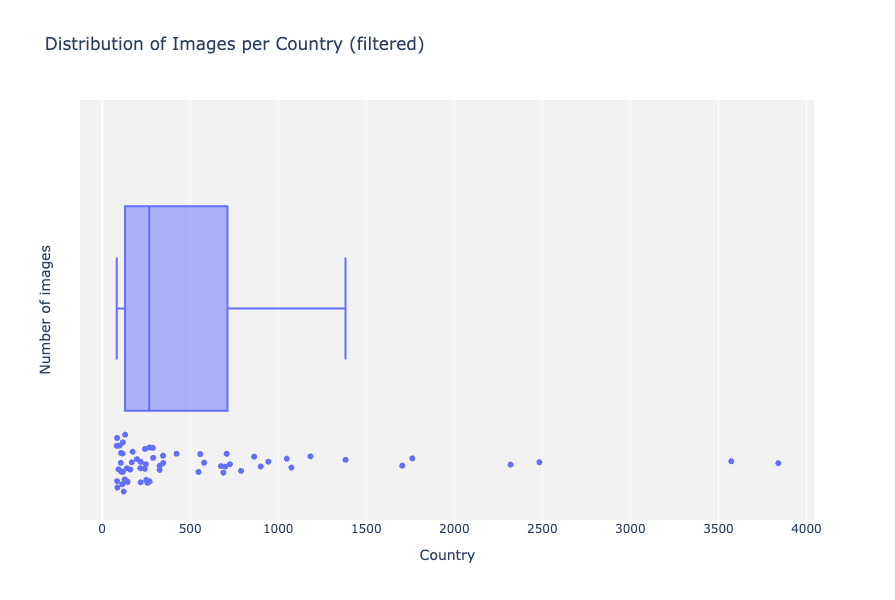

In [13]:
fig = px.box(
    df_filtered_distribution, 
    x="frequency", 
    title="Distribution of Images per Country (filtered)", 
    hover_data=["frequency"],
    points="all")

# change the dimensions of the figure
fig.update_layout(xaxis_title="Country", yaxis_title="Number of images", height=600)
fig = add_plot_styling(fig)

# Use iplot to display the graph in the Jupyter Notebook
iplot(fig)

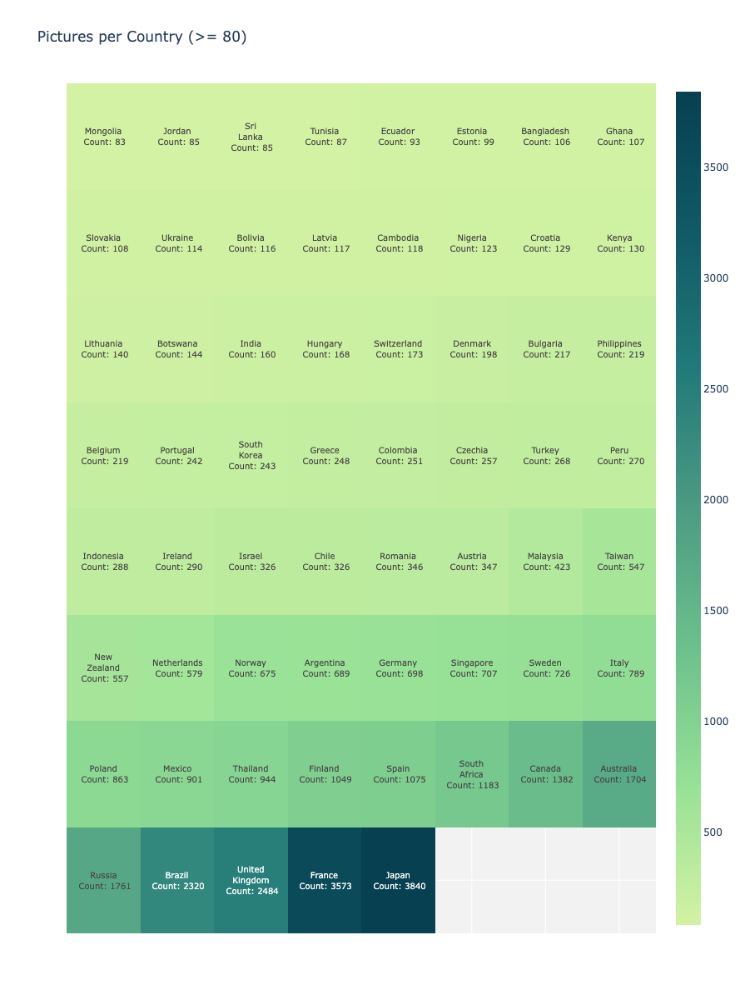

In [14]:
plot_heatmap(df_filtered_distribution.sort_values(by='frequency', ascending=True), "Pictures per Country (>= 80)", color_threshold=0.94)

----

##  Cleaned Dataset

Create a new directory with the cleaned dataset to be used for training, validation and testing of the model.

In [15]:
# Importing the train_test_split function from the scikit-learn library
from sklearn.model_selection import train_test_split

# Splitting the DataFrame 'df_filtered_geo_data' into training and testing sets
# The test set size is set to 5% of the entire dataset
train, test = train_test_split(df_filtered_geo_data, test_size=0.05, random_state=123)

In [16]:
for pathname, dataset in [
    [geo_train_dir, train],
    [geo_test_dir, test]
]:
    # make a new directory to store the filtered dataset
    pathname.mkdir(parents=True, exist_ok=True)

    # Copy the filtered dataset to the new directory
    for country in df_filtered_distribution.country.unique():
        geo_country_dir = pathname / country
        geo_country_dir.mkdir(parents=True, exist_ok=True)
        
        for picture_path in dataset[dataset.country == country].path.values:
            target_picture_path = geo_country_dir /  picture_path.name
            shutil.copy(picture_path, target_picture_path)

---

### Set Basic Parameters

Here, we set some basic parameters such as the number of epochs for training and drop out rate

In [17]:
# Number of epochs, indicating the number of complete iterations over the entire training dataset
epochs = 10

# Specify the dropout rate, which is the fraction of input units to drop during training
dropout_rate = 0.2

## Load and Prepare the Dataset

<p style="line-height:2">
Create a train and validation dataset from the filtered dataset with a 80/20 split. <br/>
The train dataset will be used to train the model, while the validation dataset will be used to identify the best model for geo location guessing.
</p>

In [18]:
# Create training and validation datasets using image_dataset_from_directory
train_df, val_df = tf.keras.utils.image_dataset_from_directory(
    geo_train_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    validation_split=0.2,
    seed=random_seed,
    subset="both",
)

# Find the number of classes in the dataset
num_classes = len(train_df.class_names)

Found 34683 files belonging to 61 classes.

Using 27747 files for training.

Using 6936 files for validation.


2023-12-15 09:28:59.398768: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro

2023-12-15 09:28:59.398800: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB

2023-12-15 09:28:59.398835: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB

2023-12-15 09:28:59.398908: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.

2023-12-15 09:28:59.398958: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


### Configure the Dataset for Performance

To ensure that our model trains efficiently, we'll configure the dataset for performance.


In [19]:
# Use TensorFlow's AUTOTUNE to automatically adjust the number of parallel calls during data preprocessing
AUTOTUNE = tf.data.AUTOTUNE

# Cache, shuffle, and prefetch the training dataset for optimized performance
train_ds = train_df.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)

# Cache and prefetch the validation dataset for optimized performance
val_ds = val_df.cache().prefetch(buffer_size=AUTOTUNE)

--------

<div style="display:flex">

<div>
<h1 style="font-weight:bold">DenseNet 121</h1>

<p style="line-height:2">
DenseNet, short for Densely Connected Convolutional Networks, is a type of deep neural network architecture designed for image classification tasks.
The "121" in DenseNet-121 refers to the specific variant of the DenseNet architecture with 121 layers.
</p><br>

<p style="line-height:2">
In a traditional convolutional neural network (CNN), information typically flows sequentially from the input layer to the output layer.
However, in DenseNet, each layer receives direct input from all preceding layers and passes its own feature maps to all subsequent layers.
The architecture is divided into dense blocks, where each layer within a dense block is connected to every other layer in that block. 
This dense connectivity helps in feature reuse and encourages the network to learn more compact and informative representations.
</p>

 <p style="line-height:2">
Reasons for choosing densenet 121 to solve the geo location classfication problem <br>
    <ul style="list-style-type:circle; line-height:2">
        <li>DenseNet-121's dense connectivity enables the extraction of rich and hierarchical spatial features, making it suitable for geo-location tasks reliant on detailed spatial patterns.</li>
        <li>DenseNet-121 is parameter-efficient due to dense connections, beneficial for tasks with limited data. Additionally, its pre-training on ImageNet facilitates effective transfer learning for geo-location applications.</li>
    </ul>
</p>

</div>

<div style="display:flex-col;  justify-content: center; align-items: center; margin: auto">
    <div style="background-color:white; padding:30px; padding-bottom: 10px;">
        <img style="padding-bottom:10px;"
            src="https://www.researchgate.net/profile/Noha-Radwan-3/publication/334170752/figure/fig5/AS:776225345785857@1562077952441/A-schematic-illustration-of-the-DenseNet-121-architecture-82.png"/>
        <p style="text-align: center; font-color:black;">
        Fig : A schematic illustration of the DenseNet-121 architecture by <a link="https://www.researchgate.net/figure/A-schematic-illustration-of-the-DenseNet-121-architecture-82_fig5_334170752" target="_blank">Noha Radwan</a>
        </p>
    </div>
</div>

</div>

<p style="font-weight:bold; font-size:20px">
Model Initialization and Configuration
</p>

In [20]:
# Create a DenseNet121 model with pre-trained weights from ImageNet
desnse_net = DenseNet121(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights="imagenet"
)

dense_model = Sequential()
dense_model.add(desnse_net)
dense_model.add(GlobalAveragePooling2D())
dense_model.add(Dense(num_classes, activation="softmax"))
dense_model.summary()

Model: "sequential"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 densenet121 (Functional)    (None, 7, 7, 1024)        7037504   

                                                                 

 global_average_pooling2d (  (None, 1024)              0         

 GlobalAveragePooling2D)                                         

                                                                 

 dense (Dense)               (None, 61)                62525     

                                                                 


Total params: 7100029 (27.08 MB)

Trainable params: 7016381 (26.77 MB)

Non-trainable params: 83648 (326.75 KB)

_________________________________________________________________


<p style="font-weight:bold; font-size:20px">
Model Compilation
</p>

In [21]:
# Compile the model with specified loss, optimizer, and metrics
dense_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

<p style="font-weight:bold; font-size:20px">
Model Training
</p>

In [22]:
# Train the model using the prepared training and validation datasets
dense_history = dense_model.fit(
    train_ds,
    epochs=epochs,
    validation_data=val_ds
)

Epoch 1/10


2023-12-15 09:29:08.059699: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.

2023-12-15 09:29:19.672806: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:422] ShuffleDatasetV3:14: Filling up shuffle buffer (this may take a while): 160 of 1000

2023-12-15 09:29:29.676318: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:422] ShuffleDatasetV3:14: Filling up shuffle buffer (this may take a while): 325 of 1000

2023-12-15 09:29:49.702428: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:422] ShuffleDatasetV3:14: Filling up shuffle buffer (this may take a while): 654 of 1000

2023-12-15 09:30:02.589897: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] Shuffle buffer filled.


868/868 [==============================] - 766s 797ms/step - loss: 2.7720 - accuracy: 0.2873 - val_loss: 4.2181 - val_accuracy: 0.1596

Epoch 2/10

868/868 [==============================] - 720s 827ms/step - loss: 2.1444 - accuracy: 0.4185 - val_loss: 2.9304 - val_accuracy: 0.3341

Epoch 3/10

868/868 [==============================] - 660s 756ms/step - loss: 1.8358 - accuracy: 0.4868 - val_loss: 3.3591 - val_accuracy: 0.2373

Epoch 4/10

868/868 [==============================] - 687s 789ms/step - loss: 1.6235 - accuracy: 0.5400 - val_loss: 2.1257 - val_accuracy: 0.4327

Epoch 5/10

868/868 [==============================] - 711s 817ms/step - loss: 1.4171 - accuracy: 0.5882 - val_loss: 2.7375 - val_accuracy: 0.3107

Epoch 6/10

868/868 [==============================] - 630s 723ms/step - loss: 1.2153 - accuracy: 0.6381 - val_loss: 2.2798 - val_accuracy: 0.4214

Epoch 7/10

868/868 [==============================] - 701s 805ms/step - loss: 1.0238 - accuracy: 0.6881 - val_loss: 2.3925 

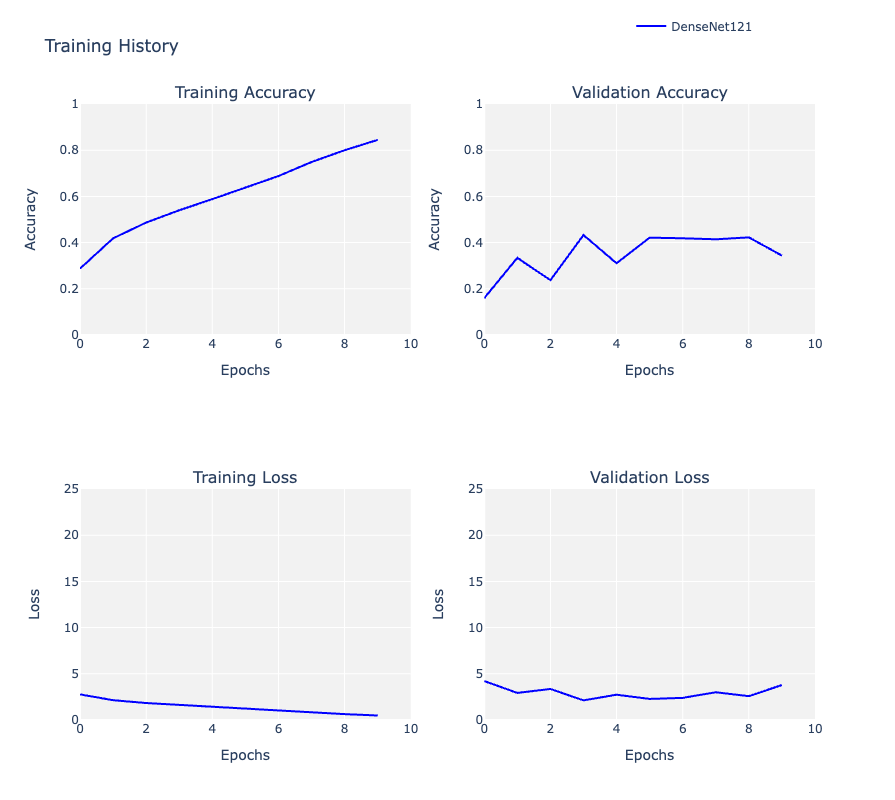

In [24]:
from plotly.subplots import make_subplots

epochs_range = [x for x in range(epochs)]

# Create a Plotly figure with subplots for accuracy and loss
fig = make_subplots(
    rows=2, 
    cols=2, 
    subplot_titles=("Training Accuracy",  "Validation Accuracy", "Training Loss", "Validation Loss")
)

plot_color = ['rgb(0, 0, 255)', 'rgb(255, 0, 0)', 'rgb(124,252,0)']

iter = 0
model_name = 'DenseNet121'
history = dense_history.history
    
# Extract training history values
acc, val_acc = history['accuracy'], history['val_accuracy']
loss, val_loss = history['loss'], history['val_loss']

# Add traces for accuracy
fig.add_trace(go.Scatter(x=epochs_range, y=acc, mode='lines', name=model_name, legendgroup=model_name, line_color=plot_color[iter]), row=1, col=1)
fig.add_trace(go.Scatter(x=epochs_range, y=val_acc, mode='lines', legendgroup=model_name, showlegend=False, line_color=plot_color[iter]), row=1, col=2)

# Add traces for loss
fig.add_trace(go.Scatter(x=epochs_range, y=loss, mode='lines', legendgroup=model_name, showlegend=False, line_color=plot_color[iter]), row=2, col=1)
fig.add_trace(go.Scatter(x=epochs_range, y=val_loss, mode='lines', legendgroup=model_name, showlegend=False, line_color=plot_color[iter]), row=2, col=2)


# Update layout for better readability
fig.update_layout(
    title_text='Training History',
    legend=dict(traceorder='normal', orientation='h', y=1.15, x=0.75, xref='paper', yref='paper'),
)

# Update y-axes titles and range for all subplots
for col in [1, 2]:
    fig.update_xaxes(title_text='Epochs', range=[0, epochs], row= col % 2 + 1, col=col)
    fig.update_xaxes(title_text='Epochs', range=[0, epochs], row= col, col=col)
    
    fig.update_yaxes(title_text='Accuracy', range=[0, 1], row=1, col=col)
    fig.update_yaxes(title_text='Loss', range=[0, 25], row=2, col=col)
    
fig.update_layout(height=800, width=1000)
fig = add_plot_styling(fig)

# Show the plot
fig.show()


----

### Load Test Dataset

In [25]:
# Create test dataset using same image size and batch size as training dataset
test_df = tf.keras.utils.image_dataset_from_directory(
    geo_test_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    seed=random_seed,
    shuffle=False
)

Found 1826 files belonging to 61 classes.


58/58 [==============================] - 13s 210ms/step


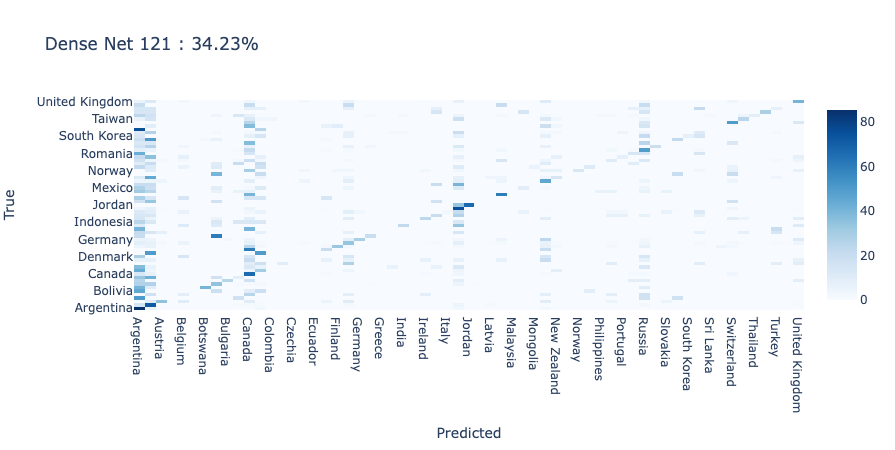

In [29]:
# get the true labels
true_labels = tf.concat([y for x, y in test_df], axis=0)

# Generate predictions
predictions = dense_model.predict(test_df)

# get the predicted labels
predicted_labels = tf.argmax(predictions, axis=1)

model_accuracy = np.mean(predicted_labels.numpy() == true_labels.numpy())

# Create confusion matrix
confusion_matrix = tf.math.confusion_matrix(
    labels=true_labels,
    predictions=predicted_labels,
    num_classes=len(test_df.class_names)
)

# Normalize confusion matrix to percentage
cm_percentage = confusion_matrix / tf.math.reduce_sum(confusion_matrix, axis=1, keepdims=True) * 100

# Create a dataframe for the heatmap
heatmap_df = pd.DataFrame(cm_percentage, columns=test_df.class_names, index=test_df.class_names)

# Create the heatmap using Plotly Express imshow
fig = go.Figure()
fig.add_trace(
    go.Heatmap(
        z=heatmap_df.values,
        x=heatmap_df.columns,
        y=heatmap_df.index,
        coloraxis='coloraxis',
        zmax=100,
        zmin=0
    )
)
fig.update_xaxes(title_text='Predicted')
fig.update_yaxes(title_text='True')

fig.update_layout(coloraxis=dict(colorscale='Blues'), title_text='{} : {:.2f}%'.format('Dense Net 121', model_accuracy * 100))
fig.show()